## Section 1: Setup & Data Loading

Download the dataset if needed, preprocess the source images and annotations, and refresh the cached `.pt` tensors. The dataset normalizes keypoints for the resized 96x96 images. We then build one shuffled training `DataLoader` and keep a fixed sample for a fair before/after comparison.

In [1]:
import os
import torch
from dataset.data import create_loaders

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_loader, val_loader, test_loader, plot_batch = create_loaders()
os.makedirs("output", exist_ok=True)


Dataset already exists. Skipping download.


## Section 2: Baseline NaimishNet Training

Train the baseline model from scratch for 10 epochs with masked mean-squared error and Adam. This model has no explicit spatial awareness. The loss is averaged over both X and Y coordinates for every valid landmark.

In [7]:
from src.train import train_with_early_stopping
from models.naimishnet import NaimishNet
import torch

baseline = NaimishNet(use_bam_and_coord=False).to(device)
optimizer = torch.optim.Adam(baseline.parameters(), lr=0.001)

history = train_with_early_stopping(
    baseline, train_loader, val_loader, optimizer, device,
    max_epochs=50, patience=5
)

torch.save(baseline.state_dict(), "output/naimishnet_aligned.pth")
print("Saved output/naimishnet_aligned.pth")

Epoch 1: train=0.052515, val=0.005608
Epoch 2: train=0.005028, val=0.004295
Epoch 3: train=0.004790, val=0.003279
Epoch 4: train=0.004747, val=0.004298
Epoch 5: train=0.004316, val=0.003004
Epoch 6: train=0.004092, val=0.002826
Epoch 7: train=0.004078, val=0.002774
Epoch 8: train=0.003949, val=0.005378
Epoch 9: train=0.003837, val=0.002766
Epoch 10: train=0.003222, val=0.002852
Epoch 11: train=0.003075, val=0.002246
Epoch 12: train=0.002894, val=0.003762
Epoch 13: train=0.002581, val=0.002053
Epoch 14: train=0.002353, val=0.001995
Epoch 15: train=0.002148, val=0.001984
Epoch 16: train=0.002034, val=0.001994
Epoch 17: train=0.001964, val=0.001944
Epoch 18: train=0.001868, val=0.001830
Epoch 19: train=0.001777, val=0.002121
Epoch 20: train=0.001765, val=0.001866
Epoch 21: train=0.001730, val=0.001820
Epoch 22: train=0.001703, val=0.001873
Epoch 23: train=0.001667, val=0.001926
Epoch 24: train=0.001640, val=0.001949
Epoch 25: train=0.001631, val=0.002253
Epoch 26: train=0.001624, val=0.00

## Section 3: Baseline Prediction (Visual Proof)

This is the “Before” picture. It plots predicted landmarks in red and valid ground-truth landmarks in green on the same fixed image, making any spatial degradation easy to see.

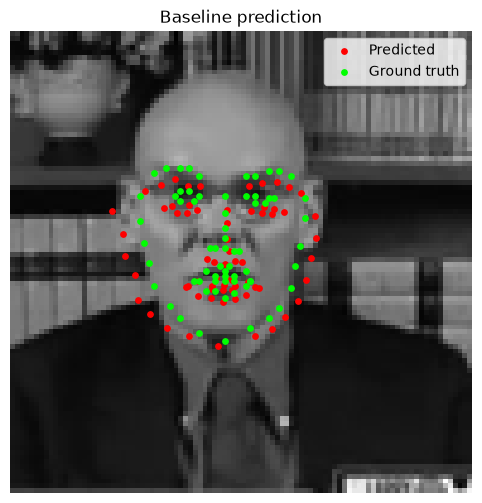

In [9]:
import matplotlib.pyplot as plt
from src.alignment_workflow import plot_prediction

baseline_for_plot = NaimishNet(use_bam_and_coord=False).to(device)
baseline_for_plot.eval()

with torch.no_grad():
    baseline_for_plot(plot_batch[0].to(device))

baseline_for_plot.load_state_dict(
    torch.load("output/naimishnet_aligned.pth", map_location=device)
)
plot_prediction(baseline_for_plot, plot_batch, device, "Baseline prediction")
plt.show()

## Section 4: Advanced Model Training (BAM + CoordConv)

Initialize the advanced model and its lazy layers, then transfer the compatible baseline convolutional weights. The first convolution is adapted for the added coordinate channels, while the regression head starts fresh. Train for 50 epochs with a lower learning rate of `0.0005`.

In [10]:
advanced = NaimishNet(use_bam_and_coord=True).to(device)
advanced.eval()

# Initialize the lazy layer, then transfer the trained baseline backbone.
with torch.no_grad():
    advanced(plot_batch[0].to(device))

from src.alignment_workflow import transfer_backbone
transfer_backbone(baseline, advanced)

optimizer = torch.optim.Adam(advanced.parameters(), lr=0.0005)

advanced_history = train_with_early_stopping(
    advanced, train_loader, val_loader, optimizer, device,
    max_epochs=50, patience=5
)

torch.save(advanced.state_dict(), "output/naimishnet_bam_coord_aligned.pth")
print("Saved output/naimishnet_bam_coord_aligned.pth")

Epoch 1: train=0.024007, val=0.003004
Epoch 2: train=0.003574, val=0.002519
Epoch 3: train=0.002959, val=0.002620
Epoch 4: train=0.002764, val=0.001759
Epoch 5: train=0.002393, val=0.002214
Epoch 6: train=0.002212, val=0.002285
Epoch 7: train=0.002190, val=0.003384
Epoch 8: train=0.002122, val=0.002737
Epoch 9: train=0.002015, val=0.001470
Epoch 10: train=0.001777, val=0.001570
Epoch 11: train=0.001723, val=0.002012
Epoch 12: train=0.001594, val=0.001821
Epoch 13: train=0.001526, val=0.001265
Epoch 14: train=0.001342, val=0.001323
Epoch 15: train=0.001318, val=0.001299
Epoch 16: train=0.001251, val=0.001207
Epoch 17: train=0.001178, val=0.001139
Epoch 18: train=0.001142, val=0.001188
Epoch 19: train=0.001140, val=0.001254
Epoch 20: train=0.001117, val=0.001233
Epoch 21: train=0.001102, val=0.001173
Epoch 22: train=0.001088, val=0.001118
Epoch 23: train=0.001092, val=0.001148
Epoch 24: train=0.001075, val=0.001204
Epoch 25: train=0.001065, val=0.001067
Epoch 26: train=0.001049, val=0.00

## Section 5: Advanced Prediction (The “After” Picture)

Visualize the final model with CoordConv and BAM on the same image as the baseline. Its keypoints should align more closely with facial features.

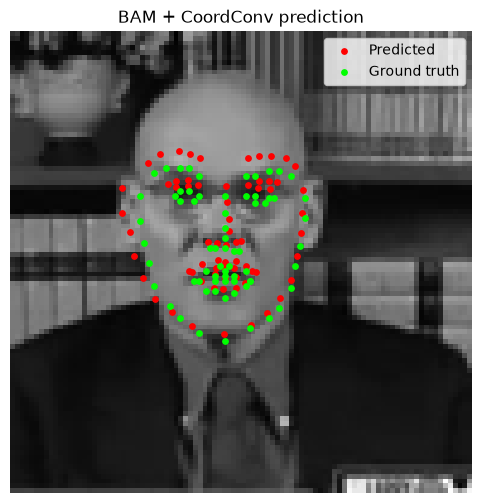

In [11]:
# Load the saved advanced weights and plot on the same image.
advanced_for_plot = NaimishNet(use_bam_and_coord=True).to(device)
advanced_for_plot.eval()
with torch.no_grad():
    advanced_for_plot(plot_batch[0].to(device))
advanced_for_plot.load_state_dict(
    torch.load("output/naimishnet_bam_coord_aligned.pth", map_location=device)
)
plot_prediction(advanced_for_plot, plot_batch, device, "BAM + CoordConv prediction")
plt.show()

In [13]:
from src.evalution import evaluate_held_out_nme

print("Baseline:", evaluate_held_out_nme(baseline, test_loader, device))
print("Advanced:", evaluate_held_out_nme(advanced, test_loader, device))

Baseline: {'nme': 0.026549292577732874, 'reduction': 'per_image', 'valid_landmarks': 52360, 'evaluated_images': 770, 'excluded_images': 0}
Advanced: {'nme': 0.022814949799954333, 'reduction': 'per_image', 'valid_landmarks': 52360, 'evaluated_images': 770, 'excluded_images': 0}
